# Supplementary Figure — HG008 PCR-free vs PCR-amplified library prep

The GIAB **HG008** tumour/normal pair sequenced twice on Illumina and run through the same
oncoanalyser 3.x pipeline:

* **PCR-free** — the public GIAB HG008 data, PCR-free library, NovaSeq 6000. This is the HG008
  Illumina run used everywhere else in the paper.
* **PCR** — HG008 worked up in our lab with a PCR-amplified library, sequenced on a NovaSeq X.

Both arms are whole-genome tumour/normal, so neither is a truth set: concordance is shown as
**overlap and uniqueness**, not TP / FP / FN.

| Panel | Content |
|-------|---------|
| **A** | REDUX overview in the Figure 2 layout — raw yield → unmapping → deduplication/consensus → post-REDUX yield → base-quality recalibration → microsatellite jitter, one row per arm |
| **B** | Variant burden, small variants at tumour VAF ≥ 10% |
| **C** | SNV and indel overlap inside the GIAB high-confidence regions, VAF ≥ 10% |

**Read the comparison with care.** The two arms differ in more than library prep: instrument
(NovaSeq 6000 vs X, which also changes the raw quality binning from Q11/25/37 to Q9/24/41) and
sequencing depth. Every panel shows the combined effect of all three.

## Data access

Both inputs are **oncoanalyser** 3.x tumour/normal run folders. The PCR-free run is the same
HG008 run that is published as

```text
gs://hartwig-oapaper-celllines/HG008/wgs/illumina_novaseq6000/bwa/tn/oa3/
```

**The PCR / NovaSeq X run is not yet in a public bucket.** Until it is, this notebook needs read
access to the location configured for it below; an unreadable run is reported and skipped
rather than fatal.

### What this notebook reads (~25 MB)

Per run folder, for the tumour and the normal:

```text
<run>/
  logs/<subject>_<sample>.redux.command.log            panel A   unmapping / duplicate stats
  bamtools/<sample>/<sample>.bam_metric.summary.tsv    panel A   yield, coverage, uniformity
  alignments/<sample>/<sample>.redux.bqr.tsv             panel A
  alignments/<sample>/<sample>.redux.ms_table.tsv.gz     panel A
  purple/<tumour>.purple.somatic.vcf.gz                panels B, C   (tumour only)
  purple/<tumour>.purple.sv.vcf.gz                     panel B
  purple/<tumour>.purple.cnv.somatic.tsv               panel B
  purple/<tumour>.purple.purity.tsv                    panel B
```

The REDUX logs are 0.1–6 MB each; only the handful of stats lines are kept in the cache.

The **GIAB high-confidence BED** is downloaded straight from the NIST GIAB FTP site over https
(10 MB, no credentials). It is the GRCh38, chr-prefixed NISTv3.3.2 HG001 high-confidence region
set — the same one the other benchmark notebooks use.

### Option 1 — read straight from the bucket (the default)

Leave the `gs://` values in the Configuration cell as they are and run all cells. Only the files
listed above are staged, into `data/`, and re-used on every later run — delete that directory to
re-fetch. You need the [Google Cloud SDK](https://cloud.google.com/sdk/docs/install) on `PATH`,
authenticated once:

```bash
gcloud auth login
```

### Option 2 — run it on your own oncoanalyser output

Point the two `run` values in the Configuration cell at any two oncoanalyser 3.x tumour/normal
run folders, local (absolute path) or `gs://`. The sample names are read from `alignments/` and
`purple/`, so they do not have to match ours.

## 1 · Configuration

In [ ]:
from pathlib import Path
from collections import OrderedDict

# ============================================================================
# CONFIGURATION — edit these to point at your own oncoanalyser output.
#
# Each arm is ONE oncoanalyser run folder (local path or gs:// URI) holding
# alignments/, bamtools/, logs/ and purple/ directly. The first arm is drawn
# first / on the left everywhere; neither arm is treated as truth.
# ============================================================================
ARMS = OrderedDict([
    ("PCR-free", {"run":   "gs://jvt-testing/runs/illumina-celllines-final/results/HG008",
                  "color": "#E08214",                 # the paper's Illumina orange
                  "label": "PCR-free · NovaSeq 6000"}),
    ("PCR",      {"run":   "gs://jvt-testing/runs/illumina-novaseqx-hg008/results/HG008",
                  "color": "#5E3C99",
                  "label": "PCR · NovaSeq X"}),
])
# GIAB high-confidence regions (GRCh38, chr-prefixed) — panel C is restricted to these.
# Downloaded over https from the NIST GIAB FTP site; no cloud credentials needed.
HIGHCONF_BED = ("https://ftp-trace.ncbi.nlm.nih.gov/ReferenceSamples/giab/release/NA12878_HG001"
                "/NISTv3.3.2/GRCh38/HG001_GRCh38_GIAB_highconf_CG-IllFB-IllGATKHC-Ion-10X-SOLID"
                "_CHROM1-X_v.3.3.2_highconf_nosomaticdel_noCENorHET7.bed")
# ============================================================================

VAF_MIN     = 0.10     # small variants: tumour FORMAT AF >= this (burden), on >= 1 arm (overlap)
LOSS_MAX_CN = 0.5      # CNA: deep loss if copyNumber <= this
GAIN_MULT   = 3.0      # CNA: high gain if copyNumber >= GAIN_MULT * ploidy
READ_TYPE   = "NONE"   # BQR / jitter rows: non-consensus reads
MIN_READS   = 20000    # jitter: skip a repeat length with fewer reads than this
MAX_LEN     = 15       # jitter: longest repeat length shown

TUMOR_SUFFIXES  = ("T",)
NORMAL_SUFFIXES = ("R", "BL")

CACHE_ROOT = Path("data") / "supplementary_figure_hg008_pcr"
EXPORT_DIR = Path("figures"); EXPORT_DIR.mkdir(parents=True, exist_ok=True)
A, B = list(ARMS)
for _a, _cfg in ARMS.items():
    print(f"{_a:9s} {_cfg['run']}")
print("VAF gate:", VAF_MIN)

## 2 · Locating pipeline output

Reads the tumour and normal sample names out of each run folder, and provides the local /
`gs://` / `https://` read helpers. Nothing is downloaded here.

In [ ]:
import subprocess, re, hashlib

# ---- IO: identical behaviour for local paths, gs:// URIs and https:// downloads ---------------
# Every gsutil call goes through _gsutil, which returns None when the target simply does not exist
# and raises on anything else (auth, permissions, typo'd bucket). A silent [] on a failed listing
# is what makes a missing-data problem look like an empty-run problem.
_MISSING = ("matched no objects", "no urls matched", "404")

def _is_remote(p):
    return str(p).startswith("gs://")

def _gsutil(*args):
    r = subprocess.run(["gsutil", *map(str, args)], capture_output=True, text=True)
    if r.returncode != 0:
        err = r.stderr.strip()
        if any(m in err.lower() for m in _MISSING):
            return None
        raise RuntimeError(f"gsutil {' '.join(map(str, args))} failed:\n{err}")
    return r.stdout

_GLOB_CACHE = {}   # listings are memoised for the session; clear it if a run folder changes

def _glob(folder, pattern, dirs_only=True):
    # Entries matching folder/pattern, without a trailing slash. '*' never crosses a '/'.
    key = (str(folder).rstrip("/"), pattern, dirs_only)
    if key not in _GLOB_CACHE:
        _GLOB_CACHE[key] = _glob_uncached(*key)
    return _GLOB_CACHE[key]

def _glob_uncached(folder, pattern, dirs_only):
    if _is_remote(folder):
        out = _gsutil("ls", "-d", f"{str(folder).rstrip('/')}/{pattern}")
        hits = [l for l in (out or "").splitlines() if l.strip()]
        if dirs_only:
            hits = [h for h in hits if h.endswith("/")]
        return sorted(h.rstrip("/") for h in hits)
    return sorted(str(p) for p in Path(folder).glob(pattern) if p.is_dir() or not dirs_only)

def _cat(src):
    if _is_remote(src):
        out = _gsutil("cat", str(src))
        if out is None:
            raise FileNotFoundError(src)
        return out
    return Path(src).read_text()

def _fetch(src, dest):
    # Copy one file into the local cache. Returns None (not an exception) when the source is
    # absent, so a run that skipped a step degrades to a blank panel instead of a crash.
    dest = Path(dest)
    if dest.exists():
        return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    if str(src).startswith(("http://", "https://")):
        # public reference files (the GIAB BED) are plain downloads, no cloud credentials needed
        import urllib.error, urllib.request
        try:
            urllib.request.urlretrieve(str(src), dest)
        except (urllib.error.URLError, OSError) as e:
            print(f"WARN: could not download {src}: {e}")
            return None
        return dest
    if _is_remote(src):
        if _gsutil("cp", str(src), str(dest)) is None:
            return None
    else:
        if not Path(src).exists():
            return None
        import shutil; shutil.copy(Path(src), dest)
    return dest

def cache_dir(root, folder, *parts):
    """Local cache path, keyed on the source folder.

    Two runs of the same subject live in different directories, so re-pointing a folder never
    silently reuses the previous run's downloaded files.
    """
    src = str(folder).rstrip("/")
    tail = [p for p in src.split("//")[-1].split("/") if p][-6:]   # readable, still unambiguous
    label = re.sub(r"[^A-Za-z0-9]+", "-", "-".join(tail)).strip("-")
    return Path(root, f"{label}-{hashlib.sha1(src.encode()).hexdigest()[:6]}", *parts)

def _classify(sample):
    # Tumour vs normal from the sample-name suffix (BL checked before R: "...BL" also ends in 'L').
    for suf in NORMAL_SUFFIXES:
        if sample.endswith(suf):
            return "N"
    for suf in TUMOR_SUFFIXES:
        if sample.endswith(suf):
            return "T"
    return None

# ---- Sample discovery -------------------------------------------------------------------------
_PURITY_SUFFIX = ".purple.purity.tsv"

def find_samples(base):
    """{"T": sample|None, "N": sample|None, "purple": tumour|None} for one run folder."""
    found = {"T": None, "N": None, "purple": None}
    for hit in _glob(base, "alignments/*"):
        sample = hit.rsplit("/", 1)[-1]
        tis = _classify(sample)
        if tis and found[tis] is None:
            found[tis] = sample
    hits = _glob(base, f"purple/*{_PURITY_SUFFIX}", dirs_only=False)
    if hits:
        found["purple"] = hits[0].rsplit("/", 1)[-1][:-len(_PURITY_SUFFIX)]
    return found

SAMPLES = {}
for _a, _cfg in ARMS.items():
    try:
        SAMPLES[_a] = find_samples(_cfg["run"])
    except RuntimeError as e:
        print(f"WARN: cannot read {_cfg['run']}\n      {str(e).strip().splitlines()[-1]}")
        continue
    print(f"{_a:9s} tumour={SAMPLES[_a]['T']}  normal={SAMPLES[_a]['N']}  "
          f"purple={SAMPLES[_a]['purple']}")
ARMS_OK = [a for a in ARMS if a in SAMPLES]

## 3 · Plotting style

In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8, "axes.titleweight": "bold",
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.8, "legend.frameon": False,
    "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42,
})

# COSMIC SBS 6-class palette
SBS_COLORS = {"C>A": "#03BCEE", "C>G": "#000000", "C>T": "#E32926",
              "T>A": "#CACACA", "T>C": "#A1CE63", "T>G": "#EDBFC2"}
SBS_ORDER = list(SBS_COLORS)

UNMAP_COLORS = OrderedDict([("high depth", "#D1495B"), ("soft-clip", "#E08214"),
                            ("chimeric", "#2C6FBB")])
DUP_CORAL = "#E4572E"
FACETS = OrderedDict([
    ("A/T",   ["A/T"]),
    ("C/G",   ["C/G"]),
    ("2 bp",  ["AT/TA", "AC/CA/GT/TG", "AG/GA/CT/TC", "CG/GC"]),
    ("≥3 bp", ["3bp repeat", "4bp repeat", "5bp repeat"]),
])
VAR_TYPES = ["SNV", "MNV", "indel", "SV", "CNA"]

# tumour above / normal below within each arm; normal is white-hatched (bars) or open (markers)
TN_OFFSET, TN_H, HATCH = 0.19, 0.34, "////"
TN_ROWS = (("T", TN_OFFSET, None), ("N", -TN_OFFSET, HATCH))
TN_HANDLES = [Patch(facecolor="#888", edgecolor="white", label="tumour"),
              Patch(facecolor="#888", edgecolor="white", hatch=HATCH, label="normal")]

def arm_handles(marker=False):
    if marker:
        return [Line2D([0], [0], marker="s", ls="", ms=7, color=ARMS[a]["color"],
                       label=ARMS[a]["label"]) for a in ARMS_OK]
    return [Patch(facecolor=ARMS[a]["color"], label=ARMS[a]["label"]) for a in ARMS_OK]

def human(n):
    n = float(n)
    for unit, div in (("B", 1e9), ("M", 1e6), ("k", 1e3)):
        if abs(n) >= div:
            return f"{n/div:.2f}{unit}"
    return f"{n:.0f}"

## 4 · Load REDUX outputs (panel A)

Per arm and tissue: the REDUX run log (unmapping reasons, duplicate and consensus-group counts),
the bamtools yield summary, and the three small REDUX tables. REDUX re-flags rather than deletes
reads, so raw reads = total reads and post-REDUX reads = those still mapped; raw coverage and
bases are grossed back up as post ÷ (1 − f), with f the unmapped fraction.

In [ ]:
import numpy as np
import pandas as pd

# ---- REDUX run-log parsing (tolerant of missing keys) ------------------------------------------
_REASON_LABEL = {"depth": "high depth", "softClip": "soft-clip", "chimeric": "chimeric"}

def parse_log_stats(text):
    s = {}
    m = re.search(r"reasons\(([^)]*)\)", text)        # reasons(depth=.. softClip=.. chimeric=..)
    if m:
        reasons = {}
        for kv in m.group(1).split():
            k, _, v = kv.partition("=")
            if v.isdigit():
                reasons[_REASON_LABEL.get(k, k)] = int(v)
        s["unmap_reasons"] = reasons
    m = re.search(r"totalReads\((\d+)\) duplicates\((\d+)\) dupGroups\((\d+)\) umiGroups\((\d+)\)", text)
    if m:
        s.update(total_reads=int(m.group(1)), duplicates=int(m.group(2)),
                 dup_groups=int(m.group(3)), umi_groups=int(m.group(4)))
    if re.search(r"duplicate marking:\s*disabled", text):
        s["dedup_disabled"] = True
    return s

def fetch_log_stats(base, sample, dest):
    # Cache only the handful of relevant REDUX log lines, then parse them. {} if there is no log.
    cache = Path(dest) / f"{sample}.logstats.txt"
    if not cache.exists():
        hits = _glob(base, f"logs/*_{sample}.redux.command.log", dirs_only=False)
        if not hits:
            print(f"WARN: no REDUX log for {sample} under {base}/logs/")
            return {}
        keep = [l for l in _cat(hits[0]).splitlines()
                if ("unmapped stats:" in l or "stats: totalReads" in l
                    or "unmapping regions from" in l or "duplicate marking:" in l)]
        cache.parent.mkdir(parents=True, exist_ok=True)
        cache.write_text("\n".join(keep))
    return parse_log_stats(cache.read_text())

# ---- bamtools yield / coverage summary ---------------------------------------------------------
_SUMMARY_MAP = OrderedDict([
    ("TotalReads", "total_reads"), ("MeanCoverage", "mean_cov"),
    ("MedianCoverage", "median_cov"), ("MadCoverage", "mad_cov"),
    ("TotalRegionBases", "total_region_bases"),
    ("DuplicatePercent", "dup_pct"), ("UnmappedPercent", "unmapped_pct"),
])

def fetch_summary_stats(base, sample, dest):
    path = _fetch(f"{base}/bamtools/{sample}/{sample}.bam_metric.summary.tsv",
                  Path(dest) / f"{sample}.summary.tsv")
    if path is None:
        print(f"WARN: no bamtools summary for {sample}")
        return {}
    df = pd.read_csv(path, sep="\t"); row = df.iloc[0]
    out = {key: float(row[col]) for col, key in _SUMMARY_MAP.items() if col in df.columns}
    if out.get("total_region_bases") and out.get("mean_cov"):
        out["total_bases_gb"] = out["mean_cov"] * out["total_region_bases"] / 1e9
    med = out.get("median_cov")
    out["uniformity"] = (out["mad_cov"] / med) if (med and out.get("mad_cov") is not None) else np.nan
    return out

# ---- REDUX tables ------------------------------------------------------------------------------
REDUX_FILES = {"bqr":            "redux.bqr.tsv",
               "ms_table":       "redux.ms_table.tsv.gz"}

def fetch_redux_tables(base, sample, dest):
    out = {}
    for key, fname in REDUX_FILES.items():
        got = _fetch(f"{base}/alignments/{sample}/{sample}.{fname}", Path(dest) / f"{sample}.{fname}")
        if got is None:
            print(f"WARN: missing {sample}.{fname}")
            out[key] = None
            continue
        out[key] = pd.read_csv(got, sep="\t", compression=("gzip" if fname.endswith(".gz") else None))
    return out

def load_redux_arm(arm):
    base = ARMS[arm]["run"]; g = {"arm": arm, "cell_line": "", "T": None, "N": None}
    for tis in ("T", "N"):
        sample = SAMPLES[arm][tis]
        if not sample:
            print(f"WARN: no {tis} sample under {base}/alignments/")
            continue
        dest = cache_dir(CACHE_ROOT, base, "redux", sample)
        if not g["cell_line"]:          # subject id = the <subject>_ prefix of the REDUX log name
            hits = _glob(base, f"logs/*_{sample}.redux.command.log", dirs_only=False)
            g["cell_line"] = hits[0].rsplit("/", 1)[-1][:-len(f"_{sample}.redux.command.log")] if hits else ""
        g[tis] = {"sample": sample, "log": fetch_log_stats(base, sample, dest),
                  "summary": fetch_summary_stats(base, sample, dest),
                  **fetch_redux_tables(base, sample, dest)}
    return g

def _yield_vals(rec):
    # Split per-sample yield into pre-REDUX (raw, derived) and post-REDUX (measured).
    sm, lg = rec["summary"], rec["log"]
    T = sm.get("total_reads"); cov = sm.get("mean_cov"); base = sm.get("total_bases_gb")
    U = sum(lg.get("unmap_reasons", {}).values()) if lg.get("unmap_reasons") else 0
    keep = 1.0 - ((U / T) if (T and U) else 0.0)
    pre  = {"reads": T, "cov": (cov / keep) if (cov and keep) else cov,
            "bases": (base / keep) if (base and keep) else base}
    post = {"reads": (T * keep) if T else None, "cov": cov, "bases": base,
            "unif": sm.get("uniformity")}
    return pre, post

def _unmap_frac(rec):
    tot = rec["summary"].get("total_reads")
    u = sum(rec["log"].get("unmap_reasons", {}).values()) if rec["log"].get("unmap_reasons") else None
    return (u / tot) if (tot and u is not None) else float("nan")

REDUX_QC = [load_redux_arm(a) for a in ARMS_OK]
for g in REDUX_QC:
    for tis in ("T", "N"):
        r = g[tis]
        if not r:
            continue
        _, post = _yield_vals(r); sm = r["summary"]
        print(f"{g['arm']:9s} {tis} [{r['sample']:>8s}] reads={human(sm.get('total_reads', 0)):>7s} "
              f"meancov={sm.get('mean_cov', float('nan')):5.1f}  unmap={_unmap_frac(r):.2%}  "
              f"dup={sm.get('dup_pct', float('nan')):.1%}  "
              f"groups={human(r['log'].get('dup_groups', 0))}")

## 5 · Load PURPLE output (panels B–C)

The tumour's PURPLE somatic VCF is read twice over: once genome-wide for the burden counts
(SNV / MNV / indel at tumour `AF ≥ VAF_MIN`, PASS only), and once restricted to the GIAB
high-confidence regions for the overlap. SV and CNA counts are not VAF-filtered.

Overlap (panel C) follows the convention of the other concordance figures: a PASS SNV or indel
enters the comparison if it reaches `AF ≥ VAF_MIN` on **at least one** arm, and is then counted
as shared if it is PASS on both — so a variant at 12% in one run and 8% in the other is shared,
not unique. Matching is on `chrom:pos:ref:alt`.

In [ ]:
import gzip
from collections import Counter

# ---- high-confidence BED: chrom -> (sorted starts, ends) ----------------------------------------
def load_highconf(bed):
    dest = _fetch(bed, CACHE_ROOT / "highconf" / str(bed).rsplit("/", 1)[-1])
    if dest is None:
        raise FileNotFoundError(f"high-confidence BED unavailable: {bed}")
    opener = gzip.open if str(dest).endswith(".gz") else open    # the public NIST copy is plain .bed
    starts, ends = {}, {}
    with opener(dest, "rt") as f:
        for line in f:
            if not line.strip() or line.startswith(("track", "browser", "#")):
                continue
            ch, s, e = line.split("\t")[:3]
            starts.setdefault(ch, []).append(int(s)); ends.setdefault(ch, []).append(int(e))
    for ch in starts:
        order = np.argsort(starts[ch])
        starts[ch] = np.asarray(starts[ch])[order]; ends[ch] = np.asarray(ends[ch])[order]
    span = sum(int((ends[c] - starts[c]).sum()) for c in starts)
    print(f"high-confidence BED: {sum(len(v) for v in starts.values()):,} intervals, "
          f"{span / 1e9:.2f} Gb over {len(starts)} contigs")
    return {"starts": starts, "ends": ends}

def in_highconf(hc, chrom, pos):
    # pos is 1-based (VCF); the BED is 0-based half-open and the variant start is the anchor.
    st = hc["starts"].get(chrom)
    if st is None:
        return False
    p0 = pos - 1
    i = int(np.searchsorted(st, p0, side="right")) - 1
    return i >= 0 and p0 < hc["ends"][chrom][i]

HC = load_highconf(HIGHCONF_BED)

def _tumor_vaf(fmt_field, sample):
    # Observed tumour VAF = FORMAT AF of the tumour (last) sample column.
    keys = fmt_field.split(":")
    if "AF" not in keys:
        return np.nan
    try:
        return float(sample.split(":")[keys.index("AF")])
    except (ValueError, IndexError):
        return np.nan

def parse_small_variants(path):
    """(counts, hc) for the PASS small variants of one somatic VCF.

    counts -- genome-wide SNV / MNV / indel counts at tumour AF >= VAF_MIN       -> panel E
    hc     -- {'snv'|'indel': {chrom:pos:ref:alt: AF}} for every PASS call inside
              the high-confidence regions, whatever its AF                        -> panel F
    """
    counts = {"SNV": 0, "MNV": 0, "indel": 0}
    hc = {"snv": {}, "indel": {}}
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            c = line.rstrip("\n").split("\t")
            if c[6] != "PASS":
                continue
            ref, alt = c[3], c[4].split(",")[0]
            kind = "snv" if (len(ref) == 1 and len(alt) == 1) else ("mnv" if len(ref) == len(alt)
                                                                     else "indel")
            vaf = _tumor_vaf(c[8], c[-1])
            if vaf == vaf and vaf >= VAF_MIN:                   # NaN-safe
                counts[{"snv": "SNV", "mnv": "MNV", "indel": "indel"}[kind]] += 1
            if kind != "mnv" and in_highconf(HC, c[0], int(c[1])):
                hc[kind][(c[0], c[1], ref, alt)] = vaf
    return counts, hc

def parse_sv(path):
    cnt = Counter()
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            c = line.split("\t")
            if c[6] != "PASS":
                continue
            m = re.search(r"SVTYPE=([A-Z]+)", c[7])
            if m:
                cnt[m.group(1)] += 1
    return dict(cnt)

def parse_cna(path, ploidy):
    cn = pd.read_csv(path, sep="\t")["copyNumber"]
    return int(((cn <= LOSS_MAX_CN) | (cn >= GAIN_MULT * ploidy)).sum())

def load_purple(arm):
    base, tumor = ARMS[arm]["run"], SAMPLES[arm]["purple"]
    if tumor is None:
        print(f"WARN: no PURPLE output under {base}/purple/ -- skipping {arm}")
        return None
    dest = cache_dir(CACHE_ROOT, base, "purple")
    want = {"som": f"{base}/purple/{tumor}.purple.somatic.vcf.gz",
            "sv":  f"{base}/purple/{tumor}.purple.sv.vcf.gz",
            "cnv": f"{base}/purple/{tumor}.purple.cnv.somatic.tsv",
            "pur": f"{base}/purple/{tumor}.purple.purity.tsv"}
    got = {k: _fetch(v, dest / v.rsplit("/", 1)[-1]) for k, v in want.items()}
    absent = [want[k].rsplit("/", 1)[-1] for k, v in got.items() if v is None]
    if absent:
        print(f"WARN: skipping {arm} -- missing PURPLE output: {', '.join(absent)}")
        return None
    counts, hc = parse_small_variants(got["som"])
    pur = pd.read_csv(got["pur"], sep="\t")
    svc = parse_sv(got["sv"])
    counts["SV"] = int(sum(svc.values()))
    counts["CNA"] = parse_cna(got["cnv"], float(pur["ploidy"].iloc[0]))
    return {"counts": counts, "hc": hc, "purity": float(pur["purity"].iloc[0]),
            "ploidy": float(pur["ploidy"].iloc[0])}

PURPLE = {}
for _a in ARMS_OK:
    _d = load_purple(_a)
    if _d is not None:
        PURPLE[_a] = _d
        print(f"{_a:9s} purity={_d['purity']:.2f} ploidy={_d['ploidy']:.2f}  "
              + "  ".join(f"{k}={v:,}" for k, v in _d["counts"].items())
              + f"  | high-conf PASS SNV={len(_d['hc']['snv']):,} indel={len(_d['hc']['indel']):,}")

# ---- overlap ------------------------------------------------------------------------------------
def overlap(kind):
    """(A only, B only, shared) for the VAF-gated PASS calls of one variant class."""
    a, b = PURPLE[A]["hc"][kind], PURPLE[B]["hc"][kind]
    gate = lambda d, k: (k in d) and d[k] == d[k] and d[k] >= VAF_MIN
    universe = {k for k in set(a) | set(b) if gate(a, k) or gate(b, k)}
    shared = sum(1 for k in universe if k in a and k in b)
    a_only = sum(1 for k in universe if k in a and k not in b)
    return a_only, len(universe) - shared - a_only, shared

if A in PURPLE and B in PURPLE:
    OVERLAP = {k: overlap(k) for k in ("snv", "indel")}
    for k, (ao, bo, sh) in OVERLAP.items():
        u = ao + bo + sh
        print(f"{k.upper():5s} {A} only={ao:,}  {B} only={bo:,}  shared={sh:,}  "
              f"({100 * sh / u:.1f}% of {u:,})")

## 6 · Panel A — REDUX overview, BQR and jitter

Left: the Figure 2 panel A read-processing columns, one row per arm, tumour above / normal below —
raw yield → unmapping → deduplication + consensus → post-REDUX yield.

Right: the two read-quality readouts with **both arms on the same axes**, so the PCR-free vs PCR
difference is read directly rather than across rows.

* **Base-quality recalibration** — Figure 2's cloud: one point per pyrimidine-normalised SBS-96
  substitution type at the run's top raw quality bin, placed at the recalibrated Q REDUX assigns
  it and coloured by class; tumour filled, normal open. The solid bar with its number is the
  sample median; the dashed grey rule is the raw quality bin the instrument assigned (Q37 on the
  NovaSeq 6000, Q41 on the NovaSeq X). The two rows behind each type (one per strand) are
  combined in error space.
* **Microsatellite jitter** — per repeat length, the deletion (top row) and insertion (bottom
  row) error rate at REDUX's microsatellite sites as a phred score `−10·log10(rate)`; higher =
  less stutter. Colour = arm, tumour filled, normal open.

Only non-consensus reads (`ReadType NONE`) are used for BQR and jitter.

PCR-free  T  raw Q37  recalibrated Q median=46.0 range=41.0-50.1  (96 types)
PCR-free  N  raw Q37  recalibrated Q median=46.1 range=40.4-50.2  (96 types)
PCR       T  raw Q41  recalibrated Q median=42.7 range=35.2-46.8  (96 types)
PCR       N  raw Q41  recalibrated Q median=42.3 range=34.7-46.3  (96 types)


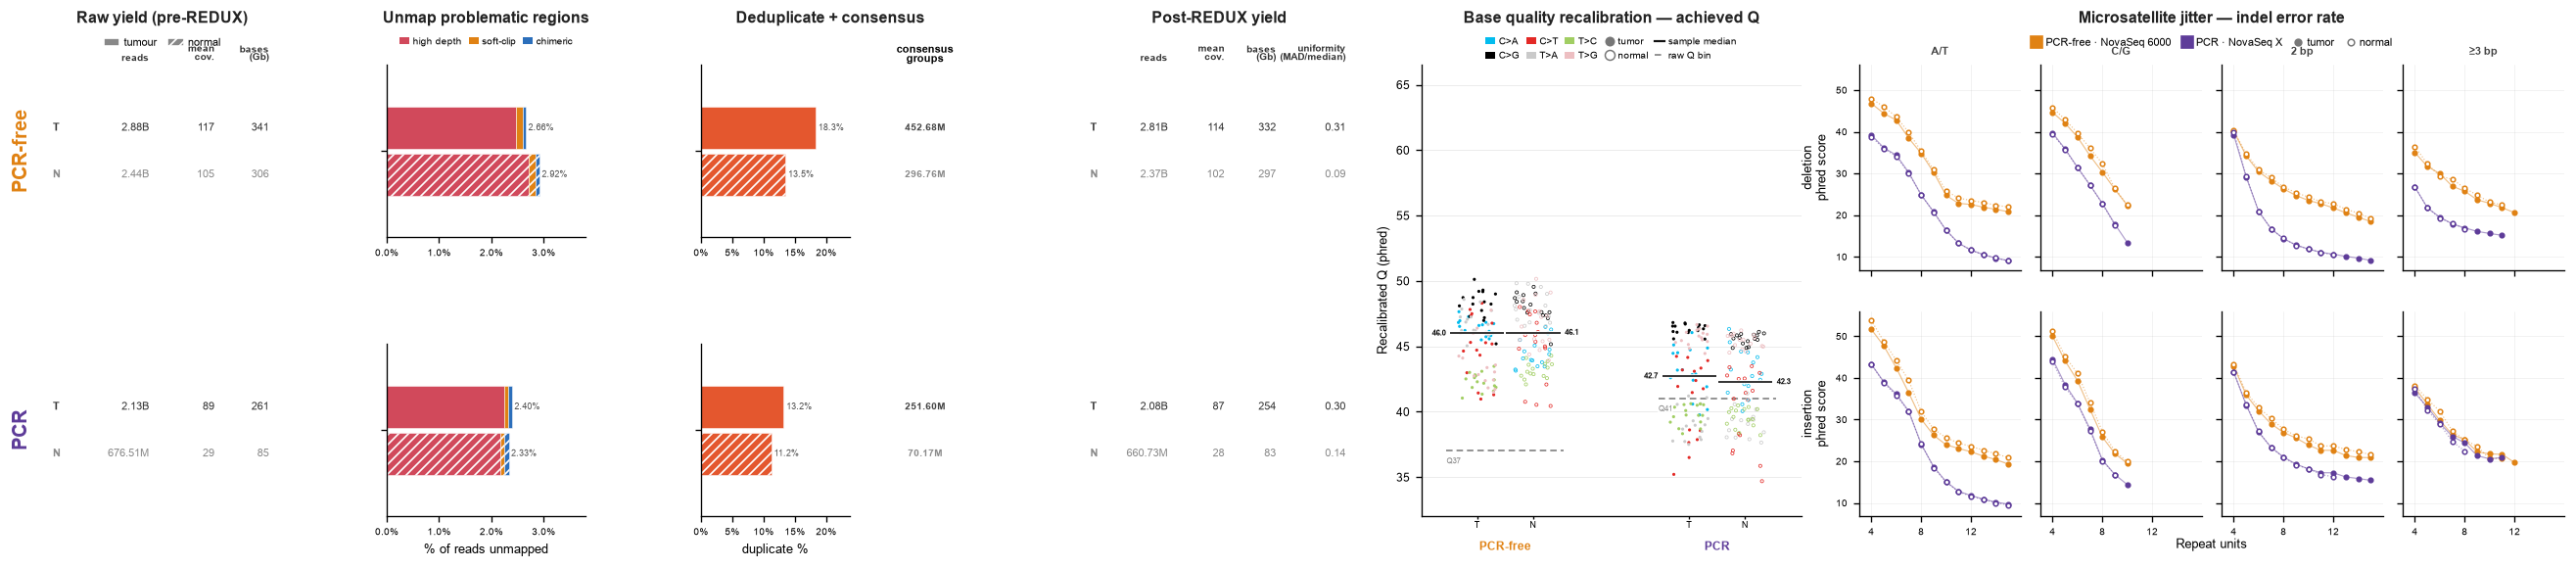

In [29]:
# ---- BQR: recalibrated Q per SBS-96 type at the top raw bin (Figure 2's bqr_sbs96) -----------
_COMP = {"A": "T", "T": "A", "C": "G", "G": "C"}

def _revcomp(seq):
    return "".join(_COMP[b] for b in reversed(seq))

def bqr_sbs96(bqr_df, read_type=READ_TYPE):
    """({(class, trinucleotide context): recalibrated Q}, raw Q) for the top quality bin.

    REDUX reports each ref>alt on both strands, so the 192 rows (12 substitutions x 16
    contexts) fold onto the 96 pyrimidine-normalised types. The two rows behind each type
    are combined in error space: averaging phred scores directly would understate the
    error rate contributed by the noisier strand.
    """
    b = bqr_df[(bqr_df["ReadType"] == read_type) & (bqr_df["Alt"] != bqr_df["Ref"])].copy()
    raw_q = int(b["OriginalQual"].max())
    b = b[b["OriginalQual"] == raw_q]
    pyr = b["Ref"].isin(("C", "T"))
    b["sbs"] = np.where(pyr, b["Ref"] + ">" + b["Alt"],
                        b["Ref"].map(_COMP) + ">" + b["Alt"].map(_COMP))
    b["ctx"] = [c if p else _revcomp(c) for c, p in zip(b["TrinucleotideContext"], pyr)]
    b["err"] = 10.0 ** (-b["RecalibratedQual"] / 10.0)
    out = {}
    for key, g in b.groupby(["sbs", "ctx"]):
        out[key] = float(-10.0 * np.log10(np.average(g["err"], weights=g["Count"])))
    return out, raw_q

# ---- jitter: {facet: DataFrame[length, phred_ins, phred_del]} (Figure 2's jitter_insdel) --------
def _dev_cols(df):
    cols = [c for c in df.columns if c.startswith("count")]
    devs = np.array([int(c.replace("count", "").replace("+", "")) for c in cols])
    o = np.argsort(devs)
    return [cols[i] for i in o], devs[o]

def jitter_insdel(ms_df, consensus=READ_TYPE):
    cols, devs = _dev_cols(ms_df)
    out = {}
    for name, units in FACETS.items():
        sub = ms_df[(ms_df["unit"].isin(units)) & (ms_df["consensusType"] == consensus)]
        rows = []
        for L, grp in sub.groupby("numUnits"):
            if L > MAX_LEN:
                continue
            c = grp[cols].to_numpy().sum(axis=0).astype(float); tot = c.sum()
            if tot < MIN_READS:
                continue
            ins = c[devs > 0].sum() / tot; dele = c[devs < 0].sum() / tot
            rows.append((int(L), (-10 * np.log10(ins) if ins > 0 else np.nan),
                         (-10 * np.log10(dele) if dele > 0 else np.nan)))
        out[name] = pd.DataFrame(rows, columns=["length", "phred_ins", "phred_del"]).sort_values("length")
    return out

for g in REDUX_QC:
    for tis in ("T", "N"):
        r = g[tis]
        if not r:
            continue
        r["bqr96"], r["raw_q"] = bqr_sbs96(r["bqr"]) if r["bqr"] is not None else (None, None)
        if r["ms_table"] is not None:
            r["jitter"] = jitter_insdel(r["ms_table"])
        if r["bqr96"]:
            v = np.array(list(r["bqr96"].values()))
            print(f"{g['arm']:9s} {tis}  raw Q{r['raw_q']}  recalibrated Q median={np.median(v):.1f} "
                  f"range={v.min():.1f}-{v.max():.1f}  ({len(v)} types)")

# ---- drawing helpers (Figure 2 panel A, one group per row) -------------------------------------
JIT_INS = "#3B6FB6"; JIT_DEL = "#C0392B"; DOT = "#555555"
UNMAP_HANDLES  = [Patch(facecolor=UNMAP_COLORS[k], label=k) for k in UNMAP_COLORS]
# BQR scatter: one 96-point cloud per sample, tumor and normal adjacent within a cell line.
BQR_PAIR_GAP = 0.62       # x distance between a cell line's tumor and normal columns
BQR_GRP_STEP = 2.35       # x distance between successive cell lines; sized so the gap holds
                          # one cell line's normal median label and the next one's tumor label
BQR_JITTER   = 0.21       # half-width of the within-column point spread
BQR_MARGIN   = 0.62       # x padding, sized to fit the median value written outside each pair
BQR_RAW_COL  = "#8C8C8C"  # raw (input) quality bin: light grey, dashed, spans the whole pair
BQR_MED_COL  = "#111111"  # sample median: near-black, solid, heavier, one column wide
BQR_RAW_DASH = (3.6, 2.2)

BQR_HANDLES = [Patch(facecolor=SBS_COLORS[s], label=s) for s in SBS_ORDER] + [
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#777", markeredgecolor="none", label="tumor"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="none", markeredgecolor="#777", markeredgewidth=0.9, label="normal"),
    Line2D([0], [0], color=BQR_MED_COL, lw=1.3, label="sample median"),
    Line2D([0], [0], color=BQR_RAW_COL, lw=1.1, dashes=BQR_RAW_DASH, label="raw Q bin"),
]
JITTER_HANDLES = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor=JIT_INS, markeredgecolor="white", label="insertion"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor=JIT_DEL, markeredgecolor="white", label="deletion"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#777", markeredgecolor="white", label="tumour"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="white", markeredgecolor="#777", markeredgewidth=0.9, label="normal"),
]

def _grp_y(ax, groups):
    n = len(groups); y = np.arange(n)[::-1]
    ax.set_ylim(-0.7, n - 0.3); ax.set_yticks(y)
    return y

def _recs(groups, tis):
    return [g[tis] for g in groups if g[tis]]

def draw_yield_panel(ax, groups, *, phase, show_header=False):
    # Text grid of sequencing yield, tumour above and normal below. phase="pre" is the derived raw
    # yield (blank without a REDUX log); phase="post" is measured, plus coverage uniformity.
    y = _grp_y(ax, groups)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_xticks([]); ax.tick_params(axis="y", length=0); ax.set_yticklabels([])
    if phase == "pre":
        cols  = [(0.44, "reads"), (0.74, "cov"), (0.99, "bases")]
        heads = [(0.44, "reads"), (0.74, "mean\ncov."), (0.99, "bases\n(Gb)")]
    else:
        cols  = [(0.30, "reads"), (0.52, "cov"), (0.72, "bases"), (0.99, "unif")]
        heads = [(0.30, "reads"), (0.52, "mean\ncov."), (0.72, "bases\n(Gb)"),
                 (0.99, "uniformity\n(MAD/median)")]
    tr = ax.get_yaxis_transform()
    for yi, g in zip(y, groups):
        for tis, off, _h in TN_ROWS:
            r = g[tis]; yy = yi + off
            col = "#333" if tis == "T" else "#8a8a8a"
            ax.text(0.0, yy, tis, va="center", ha="left", fontsize=6.4, color=col,
                    weight="bold", transform=tr)
            if not r:
                continue
            pre, post = _yield_vals(r)
            blank = (phase == "pre" and not r["log"])
            m = pre if phase == "pre" else post
            unif = m.get("unif")
            vals = {"reads": "—" if (blank or not m.get("reads")) else human(m["reads"]),
                    "cov":   ("—" if blank else f"{m['cov']:.0f}") if m.get("cov") else "—",
                    "bases": ("—" if blank else f"{m['bases']:.0f}") if m.get("bases") else "—",
                    "unif":  f"{unif:.2f}" if (unif is not None and unif == unif) else "—"}
            for x, key in cols:
                ax.text(x, yy, vals[key], va="center", ha="right", fontsize=6.4, color=col,
                        transform=tr)
    if show_header:
        for x, lab in heads:
            ax.text(x, 1.02, lab, va="bottom", ha="right", fontsize=5.8, weight="bold",
                    color="#333", transform=ax.transAxes, linespacing=0.95)

def draw_unmap_row(ax, groups, *, xmax, show_xlabel=False):
    y = _grp_y(ax, groups); tr = ax.get_yaxis_transform()
    for yi, g in zip(y, groups):
        for tis, off, hatch in TN_ROWS:
            r = g[tis]; yy = yi + off
            if not r:
                continue
            reasons = r["log"].get("unmap_reasons", {}); tot = r["summary"].get("total_reads")
            if not tot or not reasons:
                ax.text(0.01, yy, "n/a", va="center", ha="left", fontsize=5.4, color="#999",
                        transform=tr)
                continue
            left = 0.0
            for reason in UNMAP_COLORS:
                frac = reasons.get(reason, 0) / tot
                if frac > 0:
                    ax.barh(yy, frac, left=left, height=TN_H, color=UNMAP_COLORS[reason],
                            edgecolor="white", linewidth=0.3, hatch=hatch, zorder=2)
                    left += frac
            ax.text(left + xmax * 0.012, yy, f"{left:.2%}", va="center", ha="left",
                    fontsize=5.6, color="#555")
    ax.set_xlim(0, xmax); ax.tick_params(labelleft=False, labelsize=6)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=1))
    if show_xlabel:
        ax.set_xlabel("% of reads unmapped")

def draw_dedup_row(ax, groups, *, xmax, show_xlabel=False):
    y = _grp_y(ax, groups); tr = ax.get_yaxis_transform()
    for yi, g in zip(y, groups):
        for tis, off, hatch in TN_ROWS:
            r = g[tis]; yy = yi + off
            if not r:
                continue
            if r["log"].get("dedup_disabled"):
                ax.text(0.02, yy, "disabled", va="center", ha="left", fontsize=5.4, color="#999",
                        style="italic", transform=tr); continue
            dp = r["summary"].get("dup_pct")
            if dp is None:
                ax.text(0.02, yy, "n/a", va="center", ha="left", fontsize=5.4, color="#999",
                        transform=tr); continue
            ax.barh(yy, dp, height=TN_H, color=DUP_CORAL, edgecolor="white", linewidth=0.3,
                    hatch=hatch, zorder=2)
            ax.text(dp + xmax * 0.02, yy, f"{dp:.1%}", va="center", ha="left", fontsize=5.6,
                    color="#555")
    ax.set_xlim(0, xmax); ax.tick_params(labelleft=False, labelsize=6)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))
    if show_xlabel:
        ax.set_xlabel("duplicate %")

def draw_consensus_col(ax, groups, *, show_title=False):
    y = _grp_y(ax, groups); ax.set_xlim(0, 1); ax.axis("off"); tr = ax.get_yaxis_transform()
    for yi, g in zip(y, groups):
        for tis, off, _h in TN_ROWS:
            r = g[tis]; yy = yi + off
            if not r:
                continue
            lg = r["log"]
            if lg.get("dedup_disabled"):
                txt, col = "—", "#999"
            elif lg.get("dup_groups"):
                txt, col = human(lg["dup_groups"]), ("#444" if tis == "T" else "#8a8a8a")
            else:
                txt, col = "n/a", "#999"
            ax.text(0.5, yy, txt, va="center", ha="center", fontsize=6.2, weight="bold",
                    color=col, transform=tr)
    if show_title:
        ax.text(0.5, 1.0, "consensus\ngroups", ha="center", va="bottom", fontsize=6.4,
                weight="bold", transform=ax.transAxes, linespacing=1.05)

def draw_bqr_scatter(ax, groups, *, show_xlabel=False):
    """One cloud of 96 points per sample: the recalibrated Q of each substitution type.

    Points are coloured by COSMIC substitution class, tumor filled and normal open. Two rules
    are drawn, deliberately unalike so neither is mistaken for the other: a solid near-black bar
    one column wide at the sample median, with its value written outward into the gap, and a
    light dashed rule spanning the whole pair, labelled with the raw quality bin the
    recalibration is measured against -- types below that rule were over-rated by the
    instrument's own binning, which is the point of doing BQR at all.
    """
    rng = np.random.default_rng(0)          # fixed seed: the jitter is stable across re-runs
    if not any(g[t] and g[t]["bqr96"] for g in groups for t in ("T", "N")):
        ax.text(0.5, 0.5, "no REDUX BQR output\nin this run", transform=ax.transAxes,
                ha="center", va="center", fontsize=6, color="#999", style="italic")
        ax.set_xticks([]); ax.set_yticks([])
        return

    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#E8E8E8", lw=0.5, zorder=0)
    ticks, tick_lab = [], []
    for i, g in enumerate(groups):
        x0 = i * BQR_GRP_STEP
        raws = {}
        for tis, xoff in (("T", 0.0), ("N", BQR_PAIR_GAP)):
            rec = g[tis]
            if not rec or not rec["bqr96"]:
                continue
            x = x0 + xoff
            raws[x] = rec["raw_q"]
            ticks.append(x); tick_lab.append(tis)
            keys = sorted(rec["bqr96"], key=lambda k: (SBS_ORDER.index(k[0]), k[1]))
            ys   = np.array([rec["bqr96"][k] for k in keys])
            xs   = x + rng.uniform(-BQR_JITTER, BQR_JITTER, len(keys))
            cols = [SBS_COLORS[k[0]] for k in keys]
            if tis == "T":
                ax.scatter(xs, ys, s=3.6, c=cols, linewidths=0.0, zorder=3)
            else:
                ax.scatter(xs, ys, s=3.6, facecolors="none", edgecolors=cols,
                           linewidths=0.45, zorder=3)
            mv = float(np.median(ys))
            xa, xb = x - BQR_JITTER - 0.09, x + BQR_JITTER + 0.09
            for col, lw in (("white", 2.2), (BQR_MED_COL, 1.0)):   # casing keeps the bar legible
                ax.plot([xa, xb], [mv, mv], color=col, lw=lw, zorder=5,  # over black C>G points
                        solid_capstyle="butt")
            # Value written outward, into the gap between cell lines: tumor left, normal right.
            tx, tha = (xa - 0.05, "right") if tis == "T" else (xb + 0.05, "left")
            ax.text(tx, mv, f"{mv:.1f}", ha=tha, va="center", fontsize=4.6, weight="bold",
                    color=BQR_MED_COL, zorder=6,
                    bbox=dict(facecolor="white", edgecolor="none", pad=0.3, alpha=0.9))
        if not raws:
            continue
        # One raw-Q segment across the pair when both share a bin (they do within a run),
        # otherwise one per column -- Illumina mixes Q37- and Q40-binned instruments.
        spans = ([(min(raws) - BQR_JITTER - 0.13, max(raws) + BQR_JITTER + 0.13,
                   next(iter(raws.values())))] if len(set(raws.values())) == 1 else
                 [(x - BQR_JITTER - 0.13, x + BQR_JITTER + 0.13, q) for x, q in raws.items()])
        for ra, rb, q in spans:
            ax.plot([ra, rb], [q, q], color=BQR_RAW_COL, lw=1.1, zorder=2,
                    dashes=BQR_RAW_DASH)
            # Every sample carries its own bin: Illumina mixes Q37 and Q40 within a row, so a
            # reader should never have to trace back to the last labelled line.
            ax.text(ra, q - 0.5, f"Q{q}", ha="left", va="top", fontsize=5.0,
                    color=BQR_RAW_COL, zorder=5,
                    bbox=dict(facecolor="white", edgecolor="none", pad=0.6, alpha=0.85))
        ax.text(x0 + BQR_PAIR_GAP / 2, -0.055, g["cell_line"], ha="center", va="top",
                fontsize=6.0, color="#333", transform=ax.get_xaxis_transform())

    ax.set_xlim(-BQR_MARGIN,
                (len(groups) - 1) * BQR_GRP_STEP + BQR_PAIR_GAP + BQR_MARGIN)
    ax.set_xticks(ticks); ax.set_xticklabels(tick_lab, fontsize=5.6)
    ax.tick_params(axis="x", length=1.6, pad=1.2)
    ax.set_ylabel("Recalibrated Q (phred)")
    if show_xlabel:
        ax.set_xlabel("Tumor / normal", labelpad=9)

def draw_jitter_row(axes, groups, *, show_titles=False):
    for fi, name in enumerate(FACETS):
        a = axes[fi]
        for recs, fill in ((_recs(groups, "T"), True), (_recs(groups, "N"), False)):
            recs = [s for s in recs if "jitter" in s]
            if not recs:
                continue
            m = pd.concat([s["jitter"][name] for s in recs])
            if m.empty:
                continue
            m = m.groupby("length").mean(numeric_only=True).reset_index()
            for col, c in (("phred_del", JIT_DEL), ("phred_ins", JIT_INS)):
                if fill:
                    a.plot(m["length"], m[col], "o", ms=2.8, color=c, mec="white", mew=0.3)
                else:
                    a.plot(m["length"], m[col], "o", ms=2.8, mfc="white", mec=c, mew=0.9)
        if show_titles:
            a.text(0.5, 1.04, name, transform=a.transAxes, ha="center", va="bottom",
                   fontsize=6.6, weight="bold", color="#444")
        a.set_xlim(3, MAX_LEN + 1); a.set_xticks([4, 8, 12])
        a.grid(True, lw=0.3, alpha=0.3); a.tick_params(labelsize=6)
        if fi > 0:
            a.tick_params(labelleft=False)
    axes[0].set_ylabel("Phred score")

# columns: raw_yield | · | unmap | · | dedup | groups | · | post_yield
COL_W = [2.2, 0.35, 2.0, 0.35, 1.5, 0.7, 0.5, 2.6]

def draw_redux_rows(fig, spec):
    """Figure 2 panel A read-processing columns, one row per arm. Returns every axis."""
    groups_of = {g["arm"]: [g] for g in REDUX_QC}
    arms = [a for a in ARMS_OK if a in groups_of]
    recs = [g[t] for g in REDUX_QC for t in ("T", "N") if g[t]]
    unmap_xmax = max([f for f in map(_unmap_frac, recs) if f == f], default=0.02) * 1.30
    dup_xmax = max((r["summary"].get("dup_pct", 0) or 0 for r in recs
                    if not r["log"].get("dedup_disabled")), default=0.3) * 1.30

    outer = spec.subgridspec(len(arms), 1, hspace=0.62)
    rows, all_axes = [], []
    for ri, arm in enumerate(arms):
        rg = outer[ri].subgridspec(1, len(COL_W), width_ratios=COL_W, wspace=0.32)
        ax = {"pre": fig.add_subplot(rg[0]), "unmap": fig.add_subplot(rg[2]),
              "dedup": fig.add_subplot(rg[4]), "groups": fig.add_subplot(rg[5]),
              "post": fig.add_subplot(rg[7])}
        groups = groups_of[arm]
        is_top, is_bot = ri == 0, ri == len(arms) - 1
        draw_yield_panel(ax["pre"], groups, phase="pre", show_header=is_top)
        draw_unmap_row(ax["unmap"], groups, xmax=unmap_xmax, show_xlabel=is_bot)
        draw_dedup_row(ax["dedup"], groups, xmax=dup_xmax, show_xlabel=is_bot)
        draw_consensus_col(ax["groups"], groups, show_title=is_top)
        draw_yield_panel(ax["post"], groups, phase="post", show_header=is_top)
        rows.append((arm, ax))
        all_axes += [ax[k] for k in ("pre", "unmap", "dedup", "groups", "post")]
    fig.canvas.draw()

    for arm, ax in rows:                                 # arm label down the left of each row
        p = ax["pre"].get_position()
        fig.text(p.x0 - 0.012, (p.y0 + p.y1) / 2, arm, rotation=90, va="center", ha="center",
                 color=ARMS[arm]["color"], weight="bold", fontsize=12)

    top = rows[0][1]; P = {k: top[k].get_position() for k in ("pre", "unmap", "dedup", "groups",
                                                               "post")}
    yhead = max(P["pre"].y1, P["unmap"].y1) + 0.060
    def _hdr(x, txt):
        fig.text(x, yhead, txt, fontsize=9.3, weight="bold", ha="center", color="#222")
    _hdr((P["pre"].x0 + P["pre"].x1) / 2, "Raw yield (pre-REDUX)")
    _hdr((P["unmap"].x0 + P["unmap"].x1) / 2, "Unmap problematic regions")
    _hdr((P["dedup"].x0 + P["groups"].x1) / 2, "Deduplicate + consensus")
    _hdr((P["post"].x0 + P["post"].x1) / 2, "Post-REDUX yield")

    ylegend = yhead - 0.008
    fig.legend(handles=UNMAP_HANDLES, ncol=3, loc="upper center",
               bbox_to_anchor=((P["unmap"].x0 + P["unmap"].x1) / 2, ylegend), fontsize=6,
               handlelength=1.0, columnspacing=0.7, handletextpad=0.35)
    fig.legend(handles=TN_HANDLES, ncol=2, loc="upper center",
               bbox_to_anchor=((P["pre"].x0 + P["pre"].x1) / 2, ylegend), fontsize=6.5,
               handlelength=1.5, columnspacing=1.0, handletextpad=0.4)
    return all_axes, yhead

# ---- BQR + jitter, both arms on the same axes ----------------------------------------------------
def draw_jitter_overlay(fig, spec):
    """Rows deletion | insertion, one column per repeat class; colour = arm, T filled, N open."""
    sub = spec.subgridspec(2, len(FACETS), hspace=0.20, wspace=0.12)
    axes = {}; ref = None
    for ri, (col, lab) in enumerate((("phred_del", "deletion"), ("phred_ins", "insertion"))):
        for fi, name in enumerate(FACETS):
            ax = fig.add_subplot(sub[ri, fi], sharey=ref); ref = ref or ax
            for g in REDUX_QC:
                c = ARMS[g["arm"]]["color"]
                for tis in ("T", "N"):
                    r = g[tis]
                    if not r or r.get("jitter") is None:
                        continue
                    d = r["jitter"][name]
                    ax.plot(d["length"], d[col], color=c, lw=0.7, alpha=0.5,
                            ls=("-" if tis == "T" else ":"))
                    ax.plot(d["length"], d[col], "o", ms=2.8, mew=0.9, mec=c,
                            mfc=(c if tis == "T" else "white"))
            ax.set_xlim(3, MAX_LEN + 1); ax.set_xticks([4, 8, 12])
            ax.grid(True, lw=0.3, alpha=0.3); ax.tick_params(labelsize=6)
            if ri == 0:
                ax.text(0.5, 1.04, name, transform=ax.transAxes, ha="center", va="bottom",
                        fontsize=6.6, weight="bold", color="#444")
                ax.tick_params(labelbottom=False)
            if fi == 0:
                ax.set_ylabel(f"{lab}\nphred score", fontsize=7.5)
            else:
                ax.tick_params(labelleft=False)
            axes[(ri, fi)] = ax
    return [axes[k] for k in sorted(axes)]

def draw_bqr_jitter(fig, spec, yhead=None):
    """One BQR axis holding both arms' clouds, then the jitter overlay. Returns every axis."""
    sub = spec.subgridspec(1, 3, width_ratios=[2.1, 0.32, 3.9], wspace=0.0)
    axb = fig.add_subplot(sub[0, 0])
    groups = [{"cell_line": g["arm"], "T": g["T"], "N": g["N"]} for g in REDUX_QC]
    draw_bqr_scatter(axb, groups, show_xlabel=False)      # the arm names label the pairs
    recs = [g[t] for g in REDUX_QC for t in ("T", "N") if g[t]]
    # Figure 2 fixes the BQR axis at 32-66.5; widen only if these runs fall outside it.
    vals = [q for r in recs if r.get("bqr96") for q in r["bqr96"].values()] + \
           [r["raw_q"] for r in recs if r.get("raw_q")]
    axb.set_ylim(min(32, np.floor(min(vals, default=32)) - 1),
                 max(66.5, np.ceil(max(vals, default=66)) + 1))
    for t in axb.texts:                                  # arm name under each pair, in arm colour
        if t.get_text() in ARMS:
            t.set_color(ARMS[t.get_text()]["color"]); t.set_fontweight("bold"); t.set_fontsize(7)
    jax = draw_jitter_overlay(fig, sub[0, 2])
    fig.canvas.draw()

    pb, pj0, pj3 = axb.get_position(), jax[0].get_position(), jax[len(FACETS) - 1].get_position()
    if yhead is None:
        yhead = max(pb.y1, pj3.y1) + 0.060
    for x, txt in (((pb.x0 + pb.x1) / 2, "Base quality recalibration — achieved Q"),
                   ((pj0.x0 + pj3.x1) / 2, "Microsatellite jitter — indel error rate")):
        fig.text(x, yhead, txt, fontsize=9.3, weight="bold", ha="center", color="#222")
    ylegend = yhead - 0.008
    fig.legend(handles=BQR_HANDLES, ncol=5, loc="upper center",
               bbox_to_anchor=((pb.x0 + pb.x1) / 2, ylegend), fontsize=6, handlelength=1.0,
               columnspacing=0.7, handletextpad=0.35)
    fig.legend(handles=arm_handles(marker=True) + [
                   Line2D([0], [0], marker="o", ls="", ms=4, color="#777", label="tumor"),
                   Line2D([0], [0], marker="o", ls="", ms=4, mfc="white", mec="#777",
                          mew=0.9, label="normal")],
               ncol=4, loc="upper center", bbox_to_anchor=((pj0.x0 + pj3.x1) / 2, ylegend),
               fontsize=6.5, handlelength=1.0, columnspacing=1.0, handletextpad=0.35)
    pjb = jax[len(FACETS)].get_position(), jax[-1].get_position()
    fig.text((pjb[0].x0 + pjb[1].x1) / 2, pjb[0].y0 - 0.045, "Repeat units", ha="center",
             fontsize=8)
    return [axb] + jax

def draw_panel_a(fig, spec):
    """REDUX rows on the left, BQR + jitter (arms overlaid) on the right, one shared header line."""
    sub = spec.subgridspec(1, 2, width_ratios=[sum(COL_W), 9.0], wspace=0.06)
    rows, yhead = draw_redux_rows(fig, sub[0, 0])
    return rows + draw_bqr_jitter(fig, sub[0, 1], yhead=yhead)

fig = plt.figure(figsize=(22.5, 6.0))
draw_panel_a(fig, fig.add_gridspec(1, 1, left=0.04, right=0.99, top=0.78, bottom=0.14)[0, 0])
plt.show()

## 7 · Panel B — variant burden (VAF ≥ 10%)

Absolute counts for the tumour, PCR-free next to PCR. Small variants are PASS calls at tumour
`AF ≥ VAF_MIN`, genome-wide; SVs are all PASS structural variants and CNAs are deep-loss /
high-gain segments, neither of which is VAF-filtered.

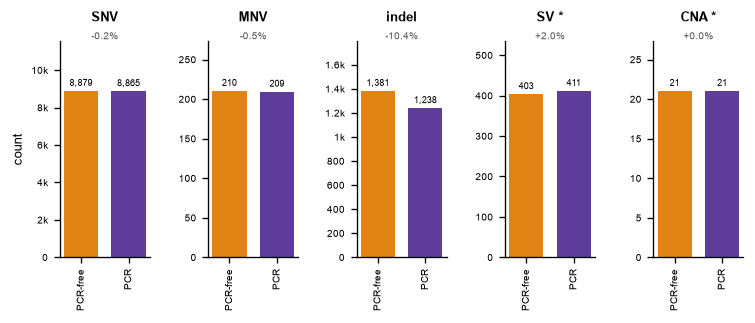

In [30]:
def draw_burden(fig, spec):
    sub = spec.subgridspec(1, len(VAR_TYPES), wspace=0.65)
    arms = [a for a in ARMS_OK if a in PURPLE]
    axes = []
    for k, vt in enumerate(VAR_TYPES):
        ax = fig.add_subplot(sub[0, k]); axes.append(ax)
        vals = [PURPLE[a]["counts"].get(vt, np.nan) for a in arms]
        x = np.arange(len(arms))
        ax.bar(x, vals, 0.72, color=[ARMS[a]["color"] for a in arms], zorder=2)
        top = max(vals) if vals else 1
        for xi, v in zip(x, vals):
            ax.text(xi, v + top * 0.02, f"{v:,}", ha="center", va="bottom", fontsize=5.6,
                    rotation=90 if v >= 10000 else 0)
        if len(vals) == 2 and vals[0]:
            ax.text(0.5, 1.0, f"{(vals[1] - vals[0]) / vals[0]:+.1%}", transform=ax.transAxes,
                    ha="center", va="bottom", fontsize=6, color="#555")
        ax.set_title(vt + (" *" if vt in ("SV", "CNA") else ""), fontsize=7.5, pad=12)
        ax.set_xticks(x); ax.set_xticklabels(arms, rotation=90, fontsize=6)
        ax.set_ylim(0, top * 1.30); ax.tick_params(axis="y", labelsize=6)
        ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _p: f"{v/1000:g}k" if v >= 1000
                                                         else f"{v:.0f}"))
    axes[0].set_ylabel("count")
    return axes

fig = plt.figure(figsize=(6.4, 3.0))
draw_burden(fig, fig.add_gridspec(1, 1, left=0.10, right=0.99, top=0.85, bottom=0.25)[0, 0])
plt.show()

## 8 · Panel C — SNV and indel overlap (GIAB high-confidence, VAF ≥ 10%)

Two-way Venn per variant class. Circles are drawn the same size whatever the counts, so read the
numbers rather than the areas. The title gives the share of the union that both runs call.

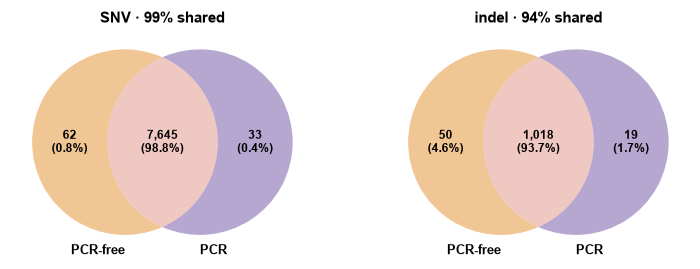

In [31]:
from matplotlib_venn import venn2
from matplotlib_venn.layout.venn2 import DefaultLayoutAlgorithm

_VENN_LAYOUT = DefaultLayoutAlgorithm(fixed_subset_sizes=(1, 1, 1))
KIND_LABEL = {"snv": "SNV", "indel": "indel"}

def draw_venns(fig, spec):
    sub = spec.subgridspec(1, 2, wspace=0.25)
    axes = []
    for j, kind in enumerate(("snv", "indel")):
        ax = fig.add_subplot(sub[0, j]); axes.append(ax)
        a_only, b_only, shared = OVERLAP[kind]; union = a_only + b_only + shared
        # venn2 subset order = (A only, B only, AB)
        v = venn2(subsets=(a_only, b_only, shared), set_labels=(A, B),
                  set_colors=(ARMS[A]["color"], ARMS[B]["color"]), alpha=0.45, ax=ax,
                  layout_algorithm=_VENN_LAYOUT)
        for key, n in (("10", a_only), ("01", b_only), ("11", shared)):
            lbl = v.get_label_by_id(key)
            if lbl:
                lbl.set_text(f"{n:,}\n({100 * n / union:.1f}%)" if union else "0")
                lbl.set_fontsize(7); lbl.set_fontweight("bold")
        for t in (v.set_labels or []):
            if t:
                t.set_fontsize(8); t.set_fontweight("bold")
        pct = 100 * shared / union if union else 0
        ax.set_title(f"{KIND_LABEL[kind]} · {pct:.0f}% shared", fontsize=9, weight="bold", pad=4)
    return axes

fig = plt.figure(figsize=(6.0, 3.0))
draw_venns(fig, fig.add_gridspec(1, 1, left=0.03, right=0.97, top=0.88, bottom=0.04)[0, 0])
plt.show()

## 9 · Composite figure

Panel letters are added when the figure is assembled for the manuscript; here each panel carries
a caption only.

Wrote: figures/supplementary_figure_hg008_pcr.pdf figures/supplementary_figure_hg008_pcr.svg figures/supplementary_figure_hg008_pcr.png


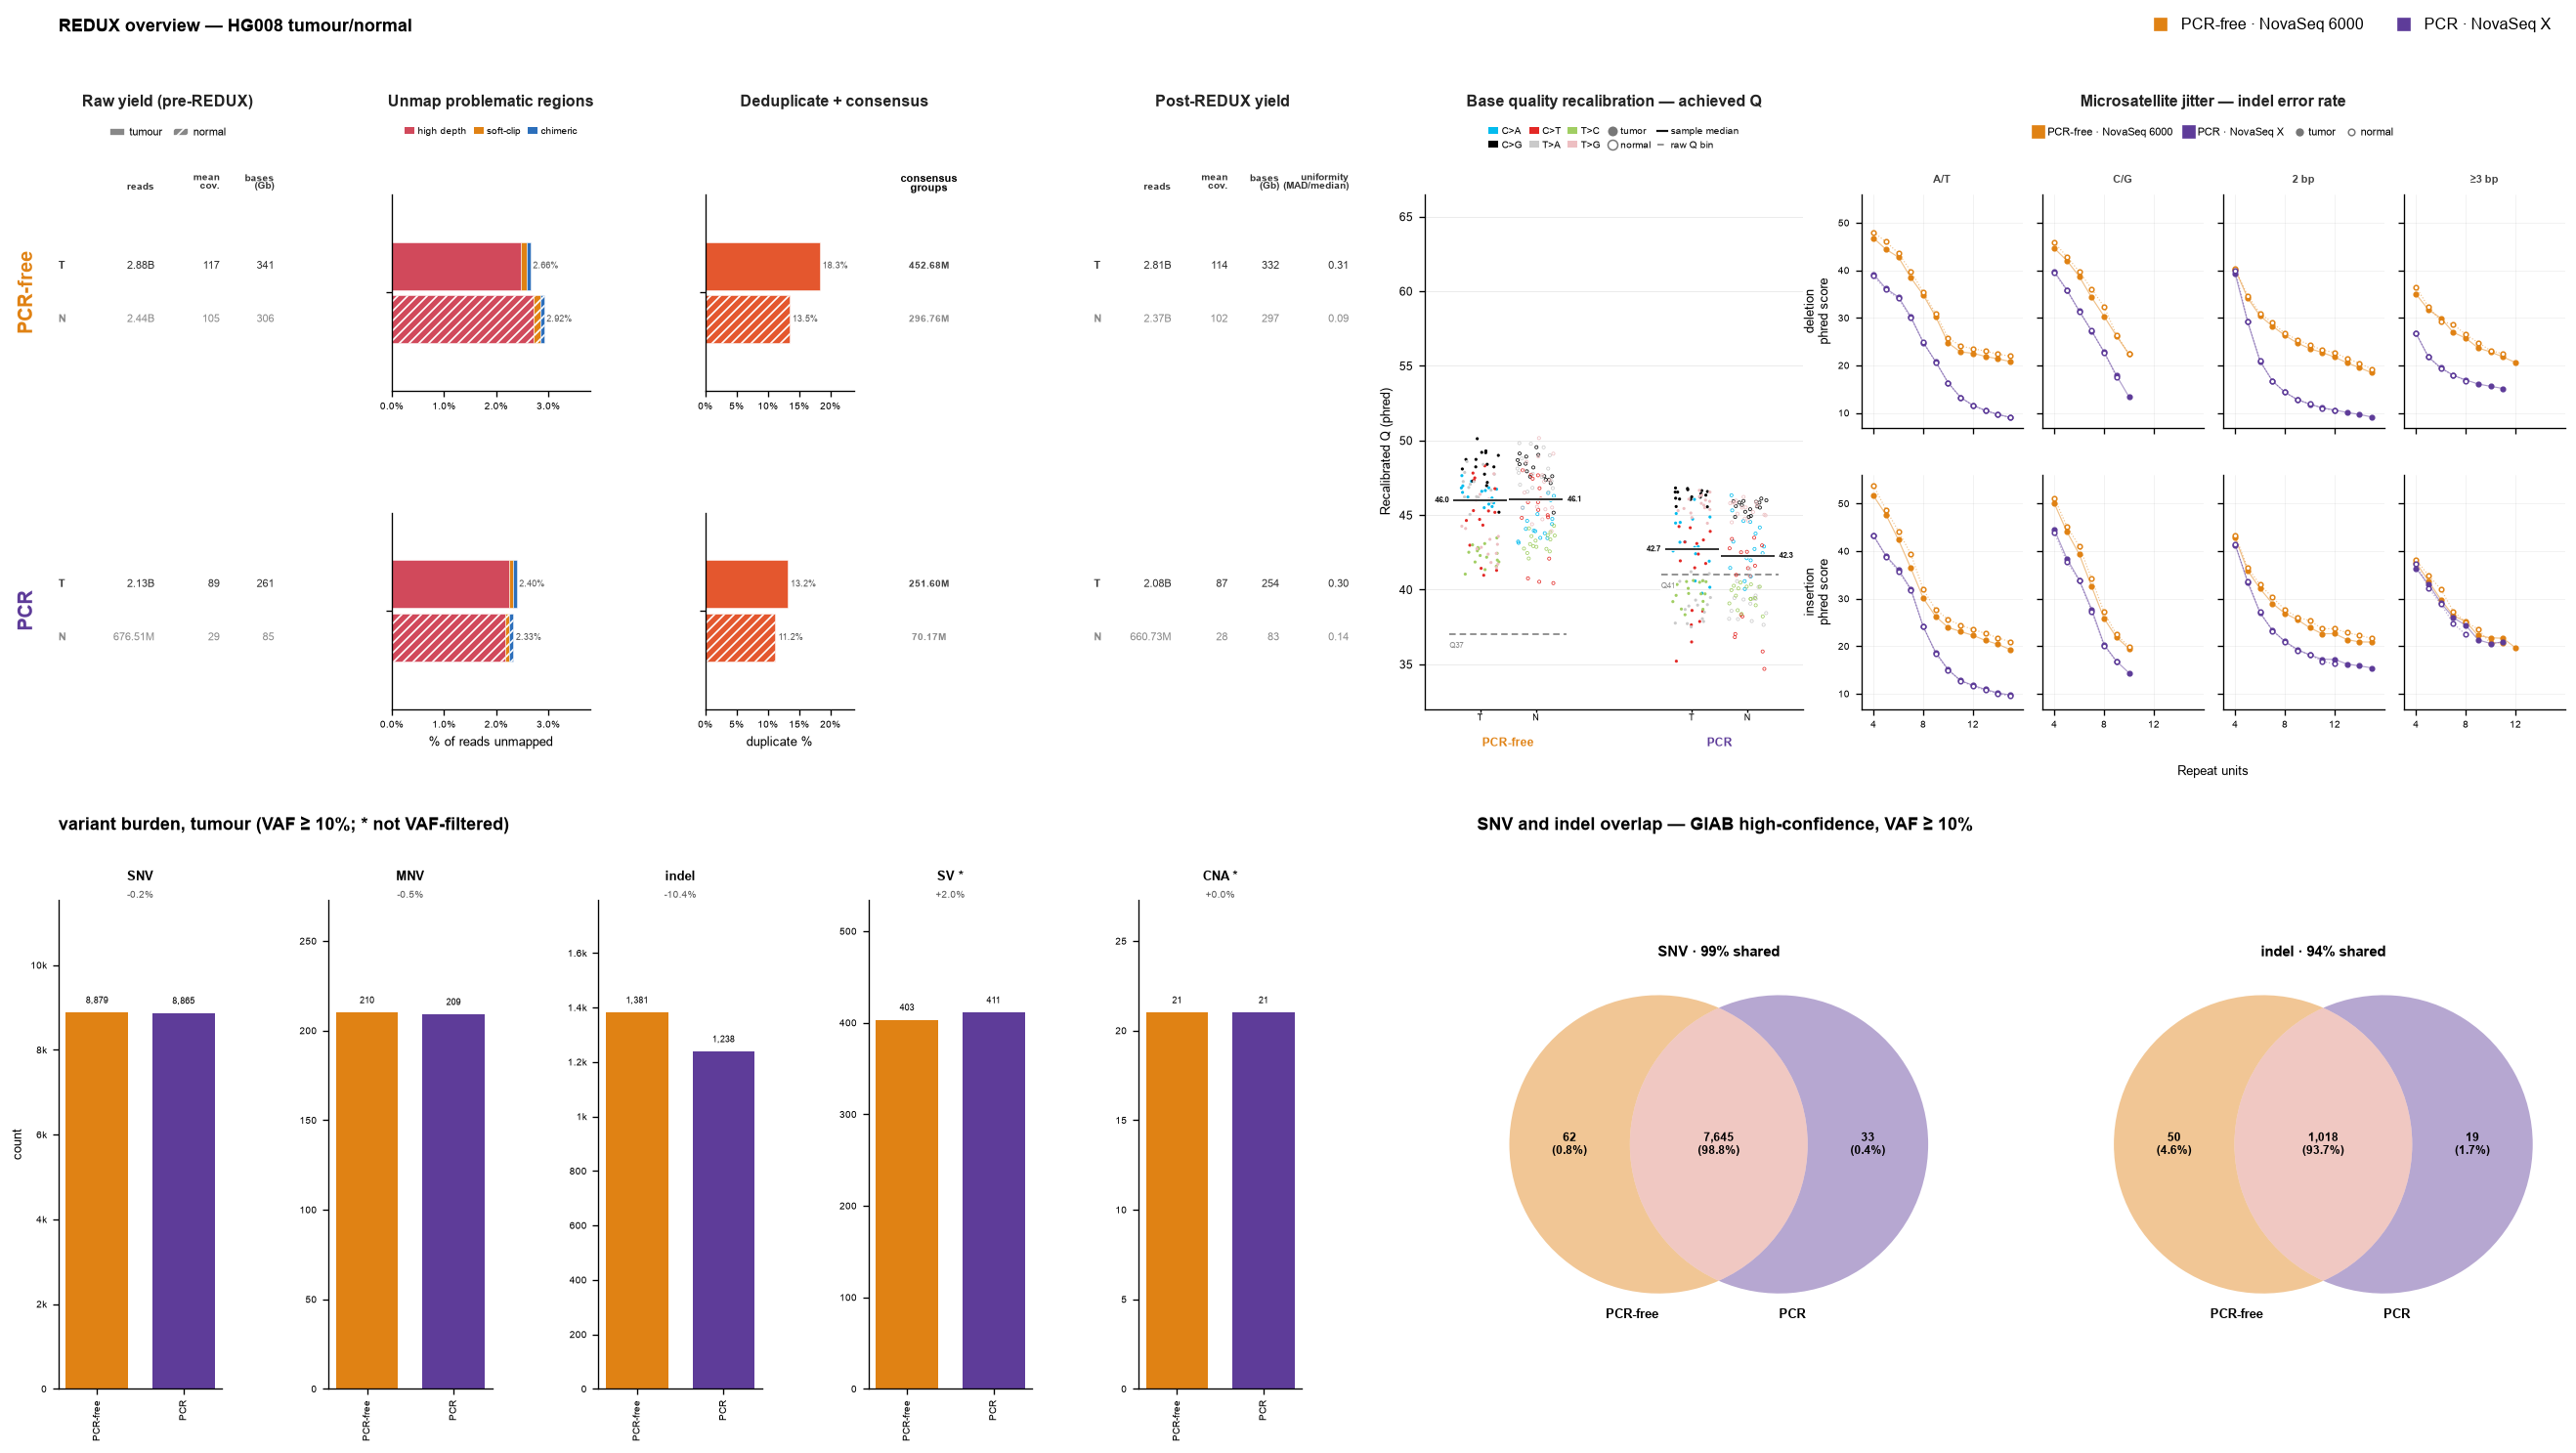

In [32]:
def composite_figure():
    fig = plt.figure(figsize=(22.5, 12.5))
    outer = fig.add_gridspec(2, 1, height_ratios=[1.0, 0.95], hspace=0.38,
                             left=0.04, right=0.99, top=0.865, bottom=0.05)
    axA = draw_panel_a(fig, outer[0, 0])
    bot = outer[1, 0].subgridspec(1, 2, width_ratios=[2.0, 1.75], wspace=0.15)
    axB = draw_burden(fig, bot[0, 0])
    axC = draw_venns(fig, bot[0, 1])

    fig.canvas.draw()
    tag = f"VAF \u2265 {VAF_MIN * 100:.0f}%"
    pA = axA[0].get_position(original=True)
    fig.text(pA.x0, 0.985, "REDUX overview — HG008 tumour/normal", fontsize=11, weight="bold",
             ha="left", va="top")
    fig.legend(handles=arm_handles(marker=True), loc="upper right", bbox_to_anchor=(0.99, 0.995),
               ncol=len(ARMS_OK), fontsize=9.5, handletextpad=0.3, columnspacing=1.6)
    # bottom-row captions share one baseline, above the tallest of the three groups
    y_bot = max(g[0].get_position(original=True).y1 for g in (axB, axC)) + 0.045
    for group, text in ((axB, f"variant burden, tumour ({tag}; * not VAF-filtered)"),
                        (axC, f"SNV and indel overlap — GIAB high-confidence, {tag}")):
        fig.text(group[0].get_position(original=True).x0, y_bot, text, fontsize=11,
                 weight="bold", ha="left", va="bottom")
    return fig

fig = composite_figure()
stem = EXPORT_DIR / "supplementary_figure_hg008_pcr"
for ext in ("pdf", "svg", "png"):
    fig.savefig(f"{stem}.{ext}", bbox_inches="tight")
print("Wrote:", *(f"{stem}.{e}" for e in ("pdf", "svg", "png")))
plt.show()